# 01 — Dataset Exploration

**Project:** Crop Yield Prediction

This notebook establishes the dataset facts used throughout the project. It records the dataset shape, feature types, target variable, missing values, duplicates, and the regression nature of the problem. **No model training is performed here.**

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "Crop Yield Data.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)

Project root: /tmp/cropsel/Crop Yield Prediction
Dataset: /tmp/cropsel/Crop Yield Prediction/data/Crop Yield Data.csv


In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
print("Initial shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Initial shape: (19689, 13)


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Avg_Temperature,Max_Temperature,Min_Temperature
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796,23.692,33.435,14.779
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710,23.692,33.435,14.779
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238,23.692,33.435,14.779
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.052,23.692,33.435,14.779
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.421,23.692,33.435,14.779


## Dataset description

The supplied file is `Crop Yield Data.csv`. The target is the continuous numerical variable **Yield**, so this is a **regression** problem. `Production` is deliberately excluded from model inputs because it is directly related to yield and would create target leakage.

In [3]:
print("Feature names and data types")
feature_table = pd.DataFrame({"Feature": df.columns, "Data Type": df.dtypes.astype(str).values, "Unique Values": df.nunique().values, "Missing Values": df.isna().sum().values})
display(feature_table)
print("\nTarget: Yield")
print("Target dtype:", df["Yield"].dtype)
print("Records:", len(df))
print("Model-input candidates:", len(df.columns)-2, "after excluding Yield and Production")

Feature names and data types


,Feature,Data Type,Unique Values,Missing Values
0,Crop,object,55,0
1,Crop_Year,int64,24,0
2,Season,object,6,0
3,State,object,30,0
4,Area,float64,13644,0
5,Production,int64,14016,0
6,Annual_Rainfall,float64,634,2
7,Fertilizer,float64,18597,2
8,Pesticide,float64,17403,2
9,Yield,float64,6174,1



Target: Yield
Target dtype: float64
Records: 19689
Model-input candidates: 11 after excluding Yield and Production


In [4]:
print("Missing-value audit")
display(pd.DataFrame({"Missing Values": df.isna().sum(), "Missing %": (df.isna().mean()*100).round(3)}))
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing-value audit


,Missing Values,Missing %
Crop,0,0.000
Crop_Year,0,0.000
Season,0,0.000
State,0,0.000
Area,0,0.000
Production,0,0.000
Annual_Rainfall,2,0.010
Fertilizer,2,0.010
Pesticide,2,0.010
Yield,1,0.005


Total missing cells: 9


Duplicate rows: 0


In [5]:
print("Target summary")
display(df["Yield"].describe().to_frame("Yield"))
print("Class distribution: Not applicable — Yield is continuous and this is a regression task.")

Target summary


,Yield
count,19688.000000
mean,79.958031
std,878.328319
min,0.000000
25%,0.600000
50%,1.030000
75%,2.389000
max,21105.000000


Class distribution: Not applicable — Yield is continuous and this is a regression task.


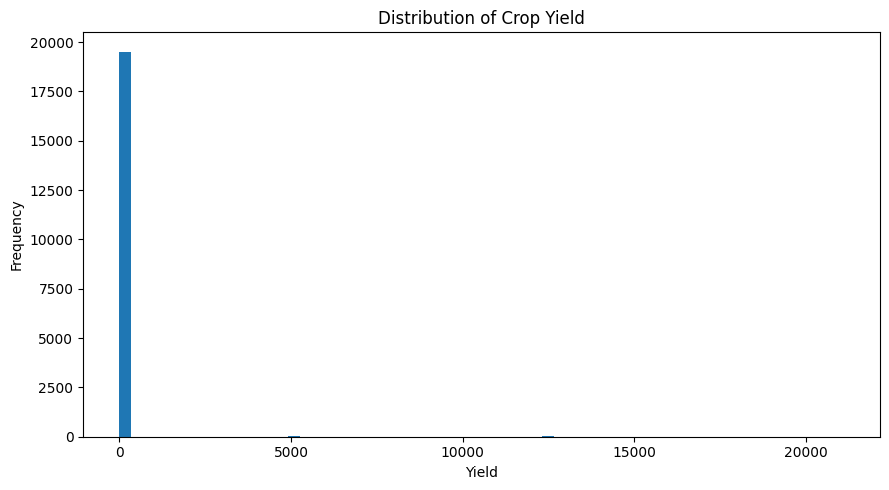

In [6]:
plt.figure(figsize=(9,5))
plt.hist(df["Yield"].dropna(), bins=60)
plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"01_yield_distribution.png", dpi=160)
plt.show()

### Key observations
- The dataset contains **19,689 rows and 13 columns** before removing the single row with missing target value.
- `Yield` is continuous, confirming a regression task.
- The dataset contains missing values in several predictor columns and one missing target value; the target row will be removed, while predictor missingness will be handled inside preprocessing pipelines.
- `Production` is excluded from modelling to prevent target leakage.